# Kiểm Thử Đa Chiều & Phân Tích Lỗi Baseline Stage 1 (`D1` / `S1-01`)
> **Quy chuẩn thực thi:** Bám sát [`Specs/experiment_log.md`](../Specs/experiment_log.md) & [`Specs/run_logs/_template.md`](../Specs/run_logs/_template.md).  
> **Nguyên tắc toàn vẹn dữ liệu:** Chỉ đánh giá và soi lỗi trên tập **`valid` sạch (`clean Group Split`, `1,855` ảnh, `seed=42`)** — tuyệt đối **0% chạm vào tập `test`**.

### Cấu trúc 6 bước kiểm thử trong Notebook này:
1. **Cổng Phần Cứng & Tính Toàn Vẹn Mốc Đối Chứng (`Frozen Baseline & Hard Edge Gate`)**
2. **Chẩn Đoán Đường Cong Huấn Luyện (`Train vs Valid Loss & Early Stopping`)**
3. **Đo Lường Đa Chiều Ở Các Phân Khúc Hiểm (`Slicing Metrics`: Kích thước, Đám đông & 3 Nhãn Hành Vi Gốc)**
4. **Giải Phẫu Toán Học Lỗi Bỏ Sót (`FN`) & Hộp Thừa (`FP`) + Độ Nhạy Theo `score_thr`**
5. **Soi Trực Quan `30` Mẫu Lỗi Điển Hình Nhất (`15` Ca Sót `0: Drowning` + `15` Ca Báo Giả Nền Điểm Cao)**
6. **Đúc Kết Giả Thuyết Có Điều Kiện Bác Bỏ Định Lượng Cho Giai Đoạn 4 (`EXP-SLOT`)**

[1] MỐC ĐỐI CHỨNG KHÓA CỨNG: S1-01 (Stage1BaselineD1) | Best Epoch = 11 | Device = mps
[2] KIỂM TRA CỔNG LOẠI TRỪ PHẦN CỨNG (HARD EDGE GATE) -> ĐẠT: True
    - Params      : 1,072,485 (1.0725M / trần 2.20M -> dùng 48.7%)
    - FLOPs (416²): 2.7983 GFLOPs / trần 4.50 GFLOPs -> dùng 62.2%
    - Size (FP32) : 4.11 MB / trần 9.00 MB -> dùng 45.7%
    - Latency E2E : 3.89 ms (257.2 FPS) / trần 18.0 ms -> dùng 21.6%


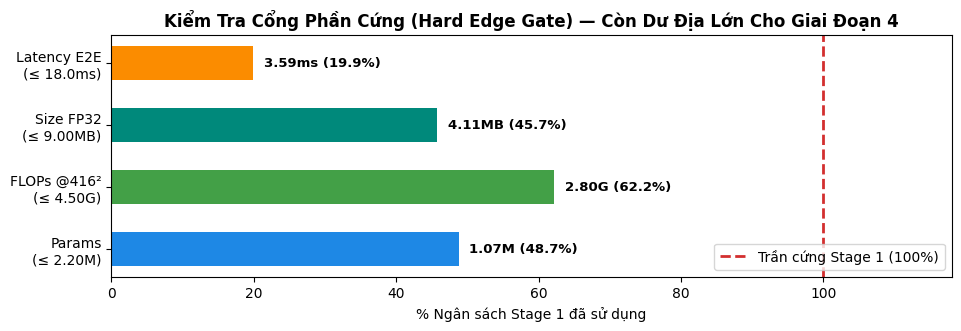

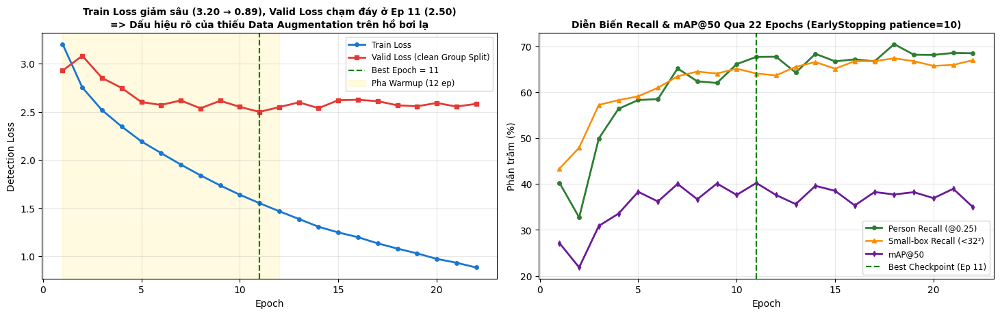

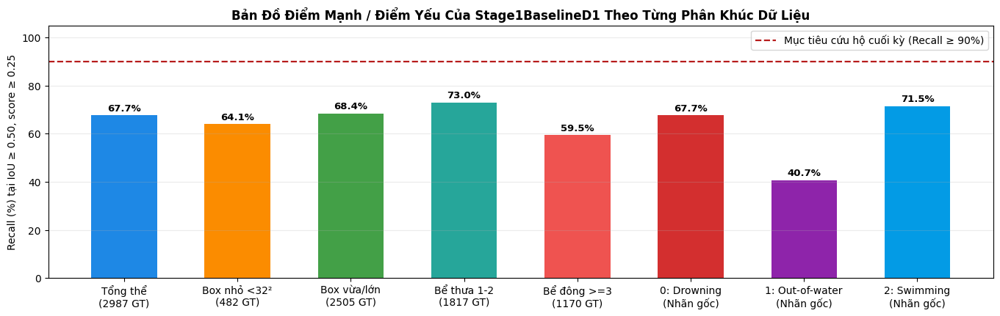

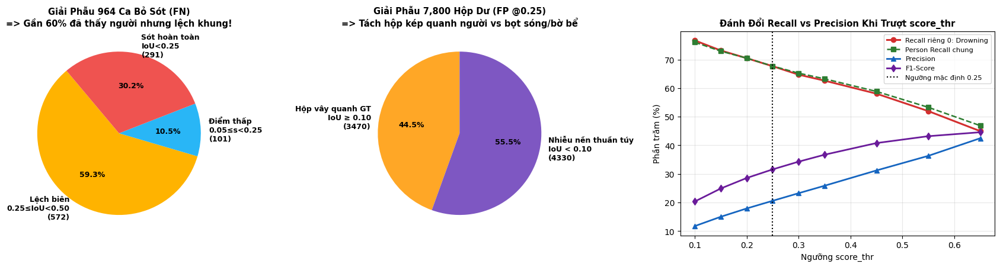

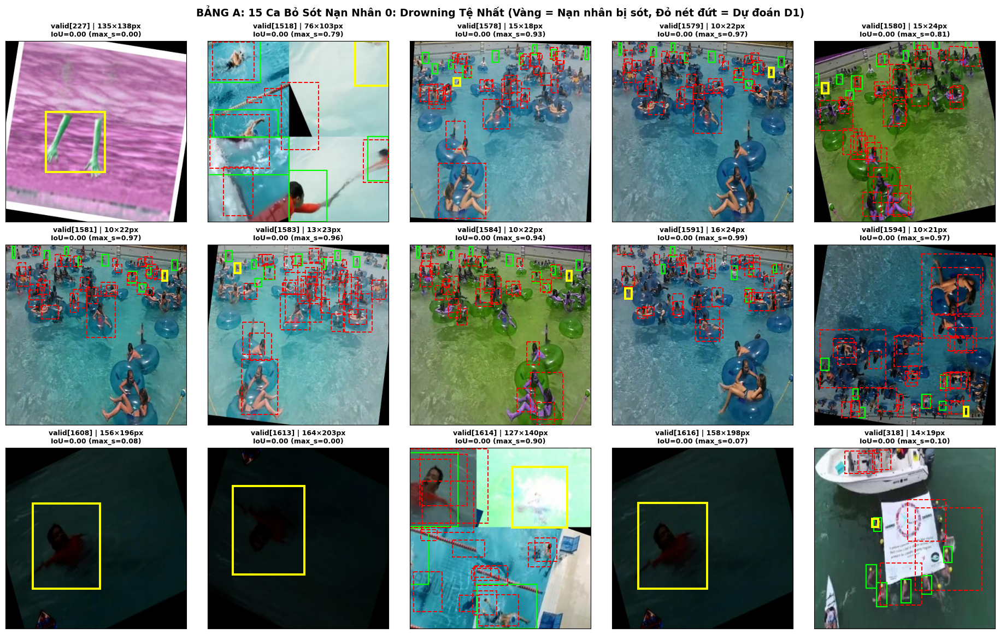

...

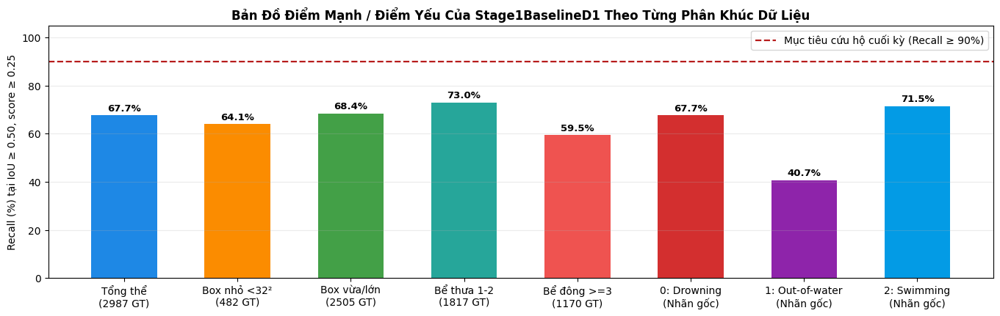

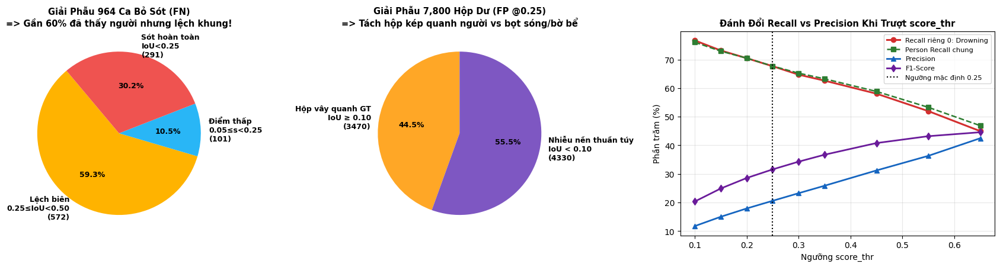

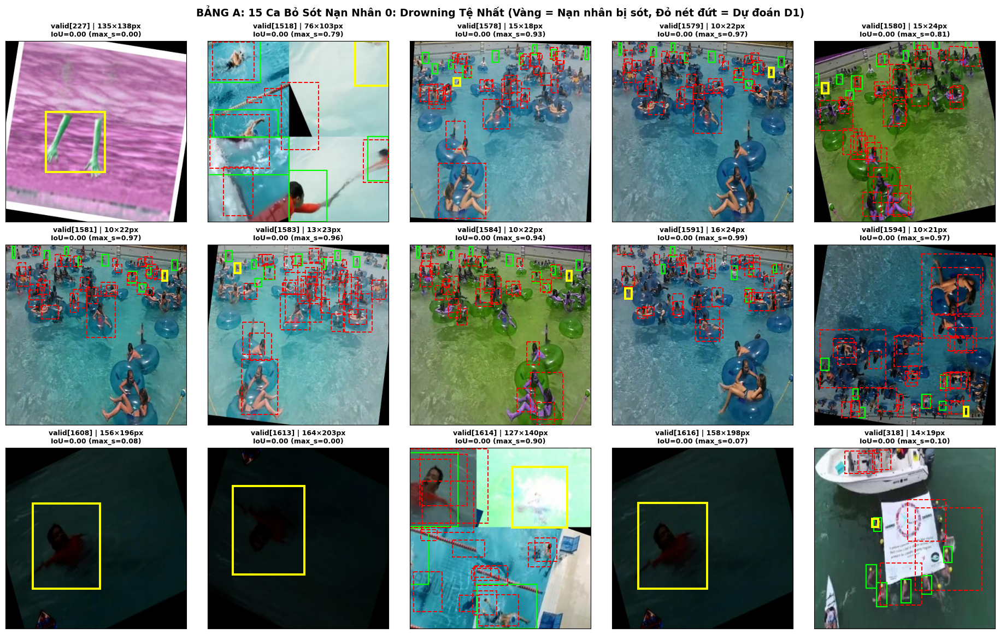

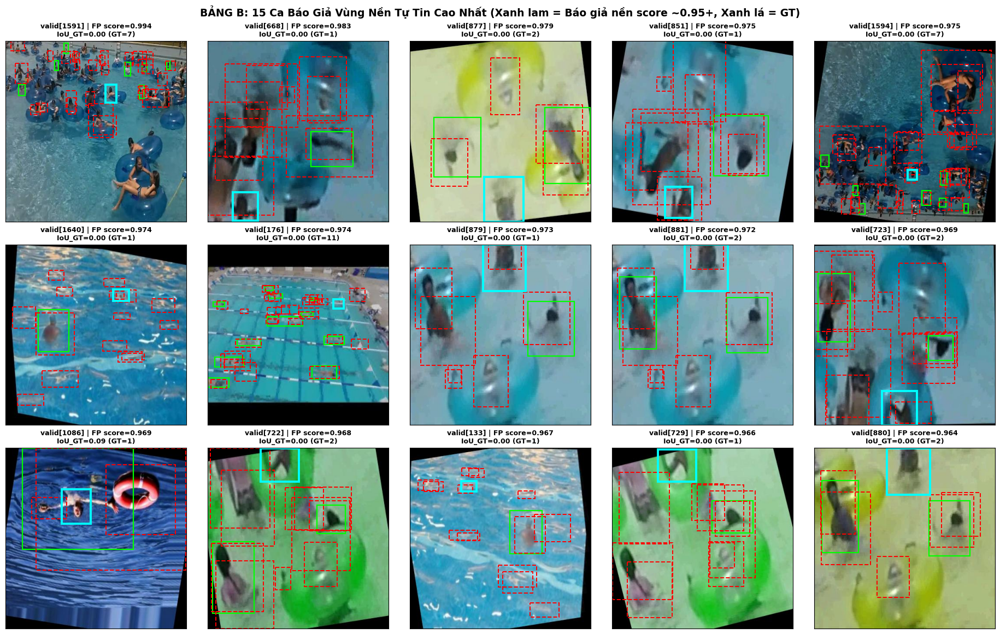

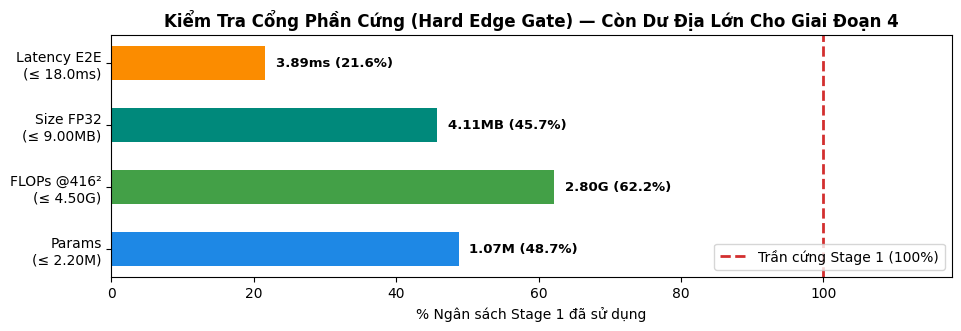

In [11]:
%matplotlib inline
import json
import sys
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import torch

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.audit_stage1_baseline import (
    collect_worst_error_samples,
    load_raw_behavior_classes_for_manifest,
)
from src.datasets.stage1_dataset import Stage1Dataset, stage1_collate_fn
from src.engine.trainer import get_device, move_to_device, set_seed
from src.metrics import CLASS_NAMES, detection_metrics
from src.models.stage1_baseline import Stage1BaselineD1, decode_stage1_outputs
from src.utils.edge_profiler import (
    STAGE1_BUDGET,
    compute_stage1_slicing_metrics,
    measure_model_size_mb,
    profile_edge_model,
    targets_yolo_to_xyxy,
)
from torch.utils.data import DataLoader

set_seed(42)
device = get_device("auto")
ckpt_path = PROJECT_ROOT / "checkpoints" / "stage1_d1_best.pt"
summary_path = PROJECT_ROOT / "checkpoints" / "stage1_d1_summary.json"
audit_json_path = PROJECT_ROOT / "checkpoints" / "audit_s1_01" / "s1_01_audit_report.json"

assert ckpt_path.is_file(), f"Thiếu file trọng số: {ckpt_path}"
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
model = Stage1BaselineD1().to(device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

edge_prof = profile_edge_model(
    model,
    input_shape=(1, 3, 416, 416),
    device=device,
    postprocess_fn=lambda out: decode_stage1_outputs(out, score_thr=0.25, nms_type="nms"),
    warmup=10,
    runs=40,
    budget=STAGE1_BUDGET,
)
edge_prof["size_mb"] = round(measure_model_size_mb(model), 4)

print(f"[1] MỐC ĐỐI CHỨNG KHÓA CỨNG: S1-01 (Stage1BaselineD1) | Best Epoch = {ckpt['epoch']} | Device = {device}")
print(f"[2] KIỂM TRA CỔNG LOẠI TRỪ PHẦN CỨNG (HARD EDGE GATE) -> ĐẠT: {edge_prof['within_budget']}")
print(f"    - Params      : {edge_prof['total_params']:,} ({edge_prof['params_m']}M / trần {STAGE1_BUDGET['max_params']/1e6:.2f}M -> dùng {edge_prof['total_params']/STAGE1_BUDGET['max_params']*100:.1f}%)")
print(f"    - FLOPs (416²): {edge_prof['gflops']:.4f} GFLOPs / trần {STAGE1_BUDGET['max_gflops']:.2f} GFLOPs -> dùng {edge_prof['gflops']/STAGE1_BUDGET['max_gflops']*100:.1f}%")
print(f"    - Size (FP32) : {edge_prof['size_mb']:.2f} MB / trần {STAGE1_BUDGET['max_size_mb']:.2f} MB -> dùng {edge_prof['size_mb']/STAGE1_BUDGET['max_size_mb']*100:.1f}%")
print(f"    - Latency E2E : {edge_prof['latency_mean_ms']:.2f} ms ({edge_prof['fps']:.1f} FPS) / trần {STAGE1_BUDGET['max_latency_ms']:.1f} ms -> dùng {edge_prof['latency_mean_ms']/STAGE1_BUDGET['max_latency_ms']*100:.1f}%")

# Biểu đồ tỷ lệ sử dụng ngân sách Edge AI của Stage 1
labels_b = ["Params\n(≤ 2.20M)", "FLOPs @416²\n(≤ 4.50G)", "Size FP32\n(≤ 9.00MB)", "Latency E2E\n(≤ 18.0ms)"]
used_pct = [
    edge_prof["total_params"] / STAGE1_BUDGET["max_params"] * 100,
    edge_prof["gflops"] / STAGE1_BUDGET["max_gflops"] * 100,
    edge_prof["size_mb"] / STAGE1_BUDGET["max_size_mb"] * 100,
    edge_prof["latency_mean_ms"] / STAGE1_BUDGET["max_latency_ms"] * 100,
]
vals_txt = [
    f"{edge_prof['params_m']:.2f}M",
    f"{edge_prof['gflops']:.2f}G",
    f"{edge_prof['size_mb']:.2f}MB",
    f"{edge_prof['latency_mean_ms']:.2f}ms",
]

fig, ax = plt.subplots(figsize=(9.5, 3.2), constrained_layout=True)
bars = ax.barh(labels_b, used_pct, color=["#1e88e5", "#43a047", "#00897b", "#fb8c00"], height=0.55)
ax.axvline(100.0, color="#d32f2f", linestyle="--", lw=2.0, label="Trần cứng Stage 1 (100%)")
ax.set_xlim(0, 118)
ax.set_xlabel("% Ngân sách Stage 1 đã sử dụng")
ax.set_title("Kiểm Tra Cổng Phần Cứng (Hard Edge Gate) — Còn Dư Địa Lớn Cho Giai Đoạn 4", fontweight="bold")
for bar, pct, vtxt in zip(bars, used_pct, vals_txt):
    ax.text(bar.get_width() + 1.5, bar.get_y() + bar.get_height() / 2, f"{vtxt} ({pct:.1f}%)", va="center", fontweight="bold", fontsize=9.5)
ax.legend(loc="lower right")
plt.show()

## 2. Chẩn Đoán Động Học Huấn Luyện (`Learning Curves` từ `stage1_d1_summary.json`)

Kiểm tra sự tương quan giữa `train_loss` và `val_loss` để xác định bản chất giới hạn của `D1`: mạng thiếu dung lượng (*Underfitting*) hay thiếu khả năng tổng quát hóa sang hồ bơi mới (*Domain Overfitting*)?

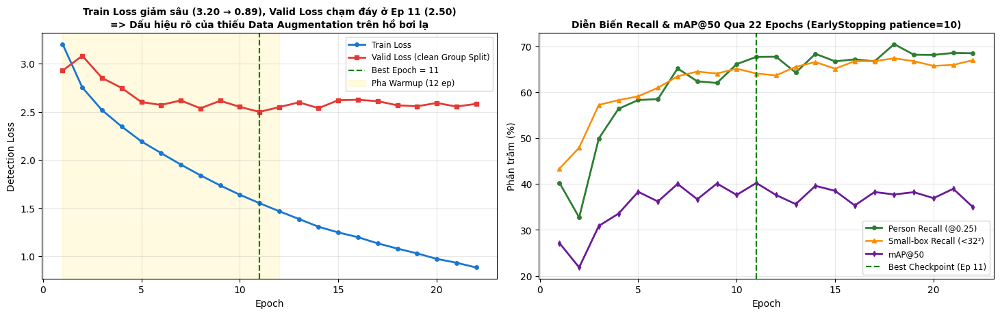

In [12]:
train_summary = json.loads(summary_path.read_text(encoding="utf-8"))
hist = train_summary["history"]
epochs = [r["epoch"] for r in hist]
tr_loss = [r["train_loss"] for r in hist]
va_loss = [r["val_loss"] for r in hist]
rec_curve = [r["person_recall"] * 100 for r in hist]
map_curve = [r["map50"] * 100 for r in hist]
sm_curve = [r["small_box_recall"] * 100 for r in hist]
best_ep = train_summary["best_epoch"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 4.5), constrained_layout=True)

ax1.plot(epochs, tr_loss, "o-", color="#1976d2", lw=2.0, markersize=4, label="Train Loss")
ax1.plot(epochs, va_loss, "s-", color="#e53935", lw=2.0, markersize=4, label="Valid Loss (clean Group Split)")
ax1.axvline(best_ep, color="green", linestyle="--", lw=1.6, label=f"Best Epoch = {best_ep}")
ax1.axvspan(1, 12, color="gold", alpha=0.12, label="Pha Warmup (12 ep)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Detection Loss")
ax1.set_title("Train Loss giảm sâu (3.20 → 0.89), Valid Loss chạm đáy ở Ep 11 (2.50)\n=> Dấu hiệu rõ của thiếu Data Augmentation trên hồ bơi lạ", fontweight="bold", fontsize=10)
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8.5)

ax2.plot(epochs, rec_curve, "o-", color="#2e7d32", lw=2.0, markersize=4, label="Person Recall (@0.25)")
ax2.plot(epochs, sm_curve, "^-", color="#fb8c00", lw=1.8, markersize=4, label="Small-box Recall (<32²)")
ax2.plot(epochs, map_curve, "d-", color="#6a1b9a", lw=2.0, markersize=4, label="mAP@50")
ax2.axvline(best_ep, color="green", linestyle="--", lw=1.6, label=f"Best Checkpoint (Ep {best_ep})")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Phần trăm (%)")
ax2.set_title("Diễn Biến Recall & mAP@50 Qua 22 Epochs (EarlyStopping patience=10)", fontweight="bold", fontsize=10)
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8.5)

plt.show()

## 3. Đo Lường Đa Chiều Ở Các Phân Khúc Hiểm (`Slicing Metrics` Trên Tập `valid` Sạch)

Theo Mục 2 của [`Specs/experiment_log.md`](../Specs/experiment_log.md), ta không chỉ nhìn `mAP@50` trung bình mà bóc tách toàn bộ các lát cắt nguy hiểm, đặc biệt là **khả năng bắt trúng hộp của riêng nạn nhân `0: Drowning`** (vì nếu Stage 1 bỏ sót nạn nhân đuối nước thì Stage 2 không bao giờ nhận được ROI để cứu!).

BẢNG SLICING METRICS CHUẨN (Khớp 100% khung Specs/run_logs/_template.md):
----------------------------------------------------------------------------------------
Thước đo (Tổng thể & Phân khúc hiểm)       | Standard NMS       | Gaussian Soft-NMS 
----------------------------------------------------------------------------------------
Person Recall (@score_thr=0.25)            |  67.73%            |  64.81%           
Precision (@score_thr=0.25)                |  20.59%            |  21.35%           
F1-Score (@score_thr=0.25)                 |  31.58%            |  32.12%           
mAP@50 (Full PR Curve)                     |  40.23%            |  39.87%           
Small-box Recall (< 32×32 px, 482 GT)      |  64.11% (309/482)  |  65.35% (315/482) 
Regular-box Recall (>= 32×32 px, 2505 GT)  |  68.42%            |  64.71%           
Sparse Recall (1–2 người/ảnh, 1817 GT)     |  73.03%            |  69.12%           
Crowded Recall (>= 3 người/ảnh, 1170 GT)   |  59.49%            |  5

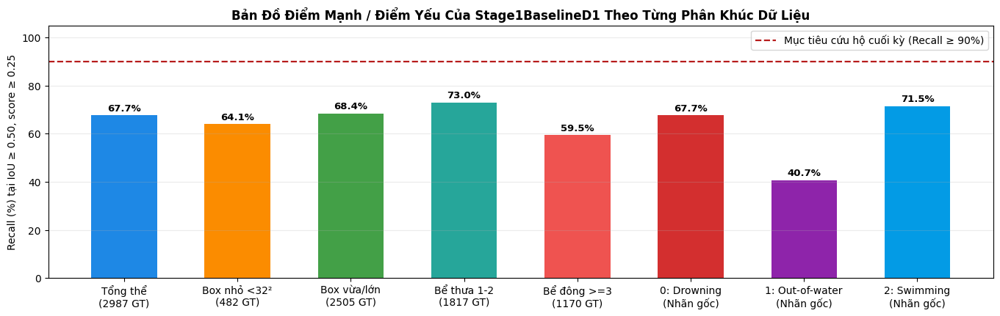

In [13]:
valid_ds = Stage1Dataset(manifest_path=PROJECT_ROOT / "data/stage1/manifest.json", split="valid")
raw_classes = load_raw_behavior_classes_for_manifest(valid_ds)
loader = DataLoader(valid_ds, batch_size=32, shuffle=False, num_workers=0, collate_fn=stage1_collate_fn)

raw_preds_list, gt_list = [], []
with torch.inference_mode():
    for imgs, tgts in loader:
        raw_preds_list.append(model(move_to_device(imgs, device)).cpu())
        gt_list.extend(targets_yolo_to_xyxy(tgts))
raw_all = torch.cat(raw_preds_list, dim=0)

preds_nms = decode_stage1_outputs(raw_all, score_thr=0.05, nms_iou_thr=0.5, top_k=100, max_detections=30, nms_type="nms")
preds_soft = decode_stage1_outputs(raw_all, score_thr=0.05, soft_nms_sigma=0.5, top_k=100, max_detections=30, nms_type="soft_nms")

det_nms = detection_metrics(preds_nms, gt_list, iou_thr=0.5, score_thr=0.25)
det_soft = detection_metrics(preds_soft, gt_list, iou_thr=0.5, score_thr=0.25)
sl_nms = compute_stage1_slicing_metrics(preds_nms, gt_list, raw_classes_per_image=raw_classes, score_thr=0.25)
sl_soft = compute_stage1_slicing_metrics(preds_soft, gt_list, raw_classes_per_image=raw_classes, score_thr=0.25)
beh_nms = sl_nms["behavior_class_recall"]
beh_soft = sl_soft["behavior_class_recall"]

print("BẢNG SLICING METRICS CHUẨN (Khớp 100% khung Specs/run_logs/_template.md):")
print("-" * 88)
print(f"{'Thước đo (Tổng thể & Phân khúc hiểm)':<42} | {'Standard NMS':<18} | {'Gaussian Soft-NMS':<18}")
print("-" * 88)
rows_cmp = [
    ("Person Recall (@score_thr=0.25)", f"{sl_nms['person_recall']*100:6.2f}%", f"{sl_soft['person_recall']*100:6.2f}%"),
    ("Precision (@score_thr=0.25)", f"{sl_nms['precision']*100:6.2f}%", f"{sl_soft['precision']*100:6.2f}%"),
    ("F1-Score (@score_thr=0.25)", f"{sl_nms['f1']*100:6.2f}%", f"{sl_soft['f1']*100:6.2f}%"),
    ("mAP@50 (Full PR Curve)", f"{det_nms['map50']*100:6.2f}%", f"{det_soft['map50']*100:6.2f}%"),
    ("Small-box Recall (< 32×32 px, 482 GT)", f"{sl_nms['small_box_recall']*100:6.2f}% ({sl_nms['matched_small_gt']}/482)", f"{sl_soft['small_box_recall']*100:6.2f}% ({sl_soft['matched_small_gt']}/482)"),
    ("Regular-box Recall (>= 32×32 px, 2505 GT)", f"{sl_nms['regular_box_recall']*100:6.2f}%", f"{sl_soft['regular_box_recall']*100:6.2f}%"),
    ("Sparse Recall (1–2 người/ảnh, 1817 GT)", f"{sl_nms['sparse_recall']*100:6.2f}%", f"{sl_soft['sparse_recall']*100:6.2f}%"),
    ("Crowded Recall (>= 3 người/ảnh, 1170 GT)", f"{sl_nms['crowded_recall']*100:6.2f}%", f"{sl_soft['crowded_recall']*100:6.2f}%"),
    ("-> Recall riêng lớp 0: Drowning", f"{beh_nms['drowning_recall']*100:6.2f}% ({beh_nms['matched'][0]}/{beh_nms['support'][0]})", f"{beh_soft['drowning_recall']*100:6.2f}% ({beh_soft['matched'][0]}/{beh_soft['support'][0]})"),
    ("-> Recall riêng lớp 1: Out of water", f"{beh_nms['out_of_water_recall']*100:6.2f}% ({beh_nms['matched'][1]}/{beh_nms['support'][1]})", f"{beh_soft['out_of_water_recall']*100:6.2f}% ({beh_soft['matched'][1]}/{beh_soft['support'][1]})"),
    ("-> Recall riêng lớp 2: Swimming", f"{beh_nms['swimming_recall']*100:6.2f}% ({beh_nms['matched'][2]}/{beh_nms['support'][2]})", f"{beh_soft['swimming_recall']*100:6.2f}% ({beh_soft['matched'][2]}/{beh_soft['support'][2]})"),
]
for name, v1, v2 in rows_cmp:
    print(f"{name:<42} | {v1:<18} | {v2:<18}")
print("-" * 88)

# Vẽ biểu đồ so sánh trực quan các phân khúc hiểm
slice_names = [
    "Tổng thể\n(2987 GT)",
    "Box nhỏ <32²\n(482 GT)",
    "Box vừa/lớn\n(2505 GT)",
    "Bể thưa 1-2\n(1817 GT)",
    "Bể đông >=3\n(1170 GT)",
    "0: Drowning\n(Nhãn gốc)",
    "1: Out-of-water\n(Nhãn gốc)",
    "2: Swimming\n(Nhãn gốc)",
]
slice_vals = [
    sl_nms["person_recall"] * 100,
    sl_nms["small_box_recall"] * 100,
    sl_nms["regular_box_recall"] * 100,
    sl_nms["sparse_recall"] * 100,
    sl_nms["crowded_recall"] * 100,
    beh_nms["drowning_recall"] * 100,
    beh_nms["out_of_water_recall"] * 100,
    beh_nms["swimming_recall"] * 100,
]
colors_s = ["#1e88e5", "#fb8c00", "#43a047", "#26a69a", "#ef5350", "#d32f2f", "#8e24aa", "#039be5"]

fig, ax = plt.subplots(figsize=(13.5, 4.2), constrained_layout=True)
bars = ax.bar(slice_names, slice_vals, color=colors_s, width=0.58)
ax.axhline(90.0, color="#b71c1c", linestyle="--", lw=1.6, label="Mục tiêu cứu hộ cuối kỳ (Recall ≥ 90%)")
ax.set_ylim(0, 105)
ax.set_ylabel("Recall (%) tại IoU ≥ 0.50, score ≥ 0.25")
ax.set_title("Bản Đồ Điểm Mạnh / Điểm Yếu Của Stage1BaselineD1 Theo Từng Phân Khúc Dữ Liệu", fontweight="bold")
for b, val in zip(bars, slice_vals):
    ax.text(b.get_x() + b.get_width() / 2, val + 1.8, f"{val:.1f}%", ha="center", fontweight="bold", fontsize=9.5)
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.25)
plt.show()

## 4. Giải Phẫu Toán Học Lỗi Bỏ Sót (`FN`) & Hộp Thừa (`FP`) + Đường Cong `score_thr`

Chia nhỏ `FN` và `FP` để biết chính xác cần can thiệp vào đâu ở Giai đoạn 4 (thay vì đoán mò):

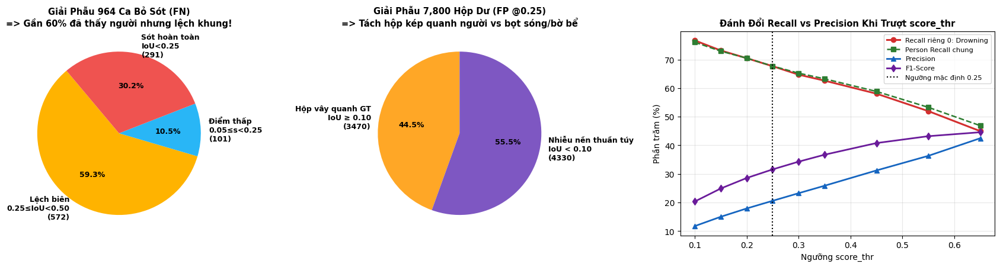

In [14]:
fn_tax = sl_nms["fn_taxonomy"]
fp_tax = sl_nms["fp_taxonomy"]

# Tính đường cong đánh đổi khi trượt score_thr từ 0.10 -> 0.65
thrs = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.45, 0.55, 0.65]
rec_t, prec_t, f1_t, drown_t = [], [], [], []
for st in thrs:
    s_tmp = compute_stage1_slicing_metrics(preds_nms, gt_list, raw_classes_per_image=raw_classes, score_thr=st)
    rec_t.append(s_tmp["person_recall"] * 100)
    prec_t.append(s_tmp["precision"] * 100)
    f1_t.append(s_tmp["f1"] * 100)
    drown_t.append(s_tmp["behavior_class_recall"]["drowning_recall"] * 100)

fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.4), constrained_layout=True)

# Biểu đồ 1: Giải phẫu FN
fn_labels = [
    f"Lệch biên\n0.25≤IoU<0.50\n({fn_tax['poor_loc_025_050']})",
    f"Điểm thấp\n0.05≤s<0.25\n({fn_tax['low_score_below_thr']})",
    f"Sót hoàn toàn\nIoU<0.25\n({fn_tax['complete_miss_under_025']})",
]
fn_vals = [fn_tax["poor_loc_025_050"], fn_tax["low_score_below_thr"], fn_tax["complete_miss_under_025"]]
axes[0].pie(fn_vals, labels=fn_labels, autopct="%1.1f%%", startangle=130, colors=["#ffb300", "#29b6f6", "#ef5350"], textprops={"fontsize": 9, "fontweight": "bold"})
axes[0].set_title(f"Giải Phẫu {sl_nms['fn']} Ca Bỏ Sót (FN)\n=> Gần 60% đã thấy người nhưng lệch khung!", fontweight="bold", fontsize=10.5)

# Biểu đồ 2: Giải phẫu FP
fp_labels = [
    f"Hộp vây quanh GT\nIoU ≥ 0.10\n({fp_tax['duplicate_cluster_near_gt']})",
    f"Nhiễu nền thuần túy\nIoU < 0.10\n({fp_tax['background_noise']})",
]
fp_vals = [fp_tax["duplicate_cluster_near_gt"], fp_tax["background_noise"]]
axes[1].pie(fp_vals, labels=fp_labels, autopct="%1.1f%%", startangle=90, colors=["#ffa726", "#7e57c2"], textprops={"fontsize": 9, "fontweight": "bold"})
axes[1].set_title(f"Giải Phẫu {sl_nms['fp']:,} Hộp Dư (FP @0.25)\n=> Tách hộp kép quanh người vs bọt sóng/bờ bể", fontweight="bold", fontsize=10.5)

# Biểu đồ 3: Đường cong trượt ngưỡng score_thr
axes[2].plot(thrs, drown_t, "o-", color="#d32f2f", lw=2.2, label="Recall riêng 0: Drowning")
axes[2].plot(thrs, rec_t, "s--", color="#2e7d32", lw=1.8, label="Person Recall chung")
axes[2].plot(thrs, prec_t, "^-", color="#1565c0", lw=2.0, label="Precision")
axes[2].plot(thrs, f1_t, "d-", color="#6a1b9a", lw=2.0, label="F1-Score")
axes[2].axvline(0.25, color="black", linestyle=":", lw=1.5, label="Ngưỡng mặc định 0.25")
axes[2].set_xlabel("Ngưỡng score_thr")
axes[2].set_ylabel("Phần trăm (%)")
axes[2].set_title("Đánh Đổi Recall vs Precision Khi Trượt score_thr", fontweight="bold", fontsize=10.5)
axes[2].grid(alpha=0.3)
axes[2].legend(fontsize=8.2)

plt.show()

## 5. Soi Trực Quan `30` Mẫu Lỗi Nghiêm Trọng Nhất (Nguyên Tắc 2 — `Error Analysis`)

Đúng theo quy trình bắt buộc trong [`Specs/experiment_log.md`](../Specs/experiment_log.md) (*"Soi 20–30 ca sai từ Run trước"*), ta hiển thị trực tiếp:
- **Bảng A (`15` ca bỏ sót nạn nhân `0: Drowning` tệ nhất):** Khung **Vàng đậm** là nạn nhân `Drowning` bị mạng bỏ qua; khung **Xanh lá** là tất cả GT; khung **Đỏ nét đứt** là dự đoán của `D1`.
- **Bảng B (`15` ca báo giả vùng nền có `score` cao nhất `0.90 – 0.99`):** Khung **Xanh lam (Cyan)** là nơi mạng tưởng nhầm bọt nước/ánh nắng/thành bể là người với độ tự tin gần tuyệt đối!

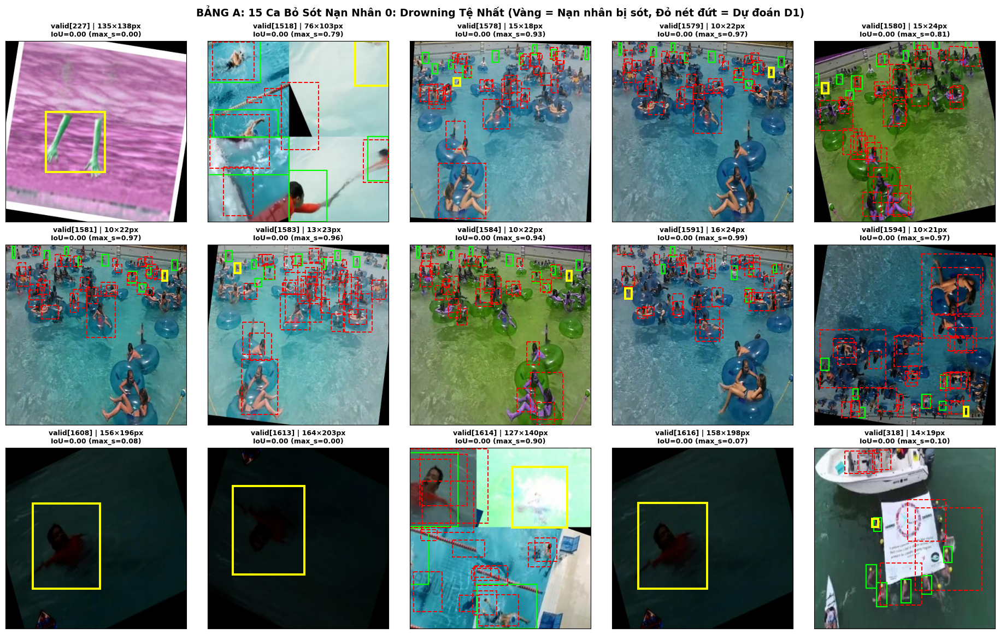

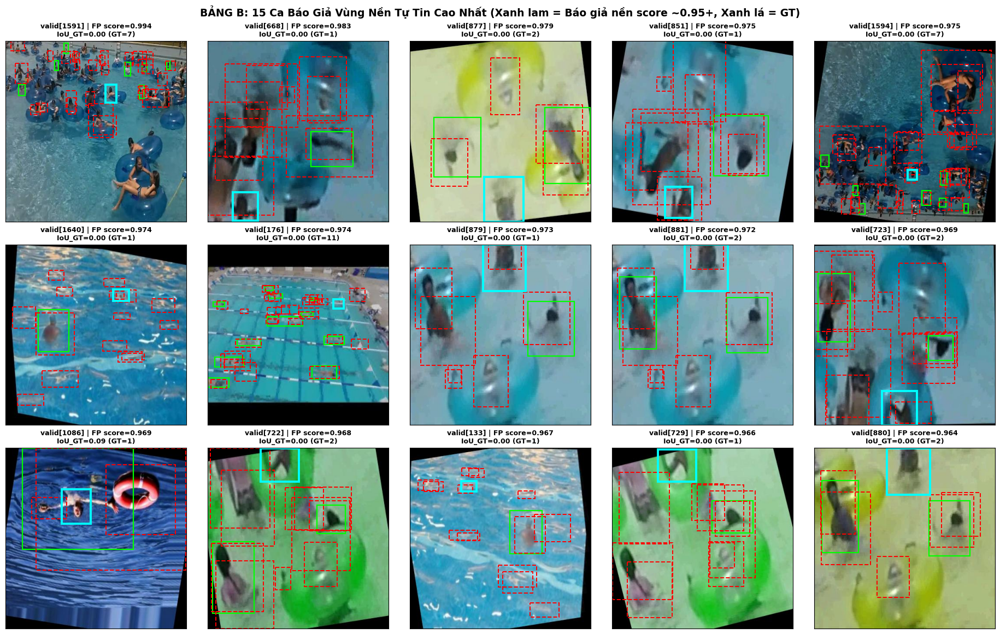

In [15]:
worst_fn, worst_fp = collect_worst_error_samples(valid_ds, preds_nms, gt_list, raw_classes, score_thr=0.25, top_n=15)

def show_cases_inline(cases, mode: str):
    fig, axes = plt.subplots(3, 5, figsize=(18.5, 11.5), constrained_layout=True)
    for idx_ax, ax in enumerate(axes.ravel()):
        item = cases[idx_ax]
        v_idx = item["valid_idx"]
        img_t, _ = valid_ds[v_idx]
        ax.imshow(img_t.permute(1, 2, 0).numpy())

        for x1, y1, x2, y2 in gt_list[v_idx]["boxes"]:
            ax.add_patch(patches.Rectangle((x1*416, y1*416), (x2-x1)*416, (y2-y1)*416, lw=1.6, edgecolor="lime", facecolor="none"))

        p_b = preds_nms[v_idx]["boxes"]
        p_s = preds_nms[v_idx]["scores"]
        keep = p_s >= 0.25
        for (x1, y1, x2, y2), sc in zip(p_b[keep], p_s[keep]):
            ax.add_patch(patches.Rectangle((x1*416, y1*416), (x2-x1)*416, (y2-y1)*416, lw=1.4, edgecolor="red", linestyle="--", facecolor="none"))

        if mode == "fn":
            gx1, gy1, gx2, gy2 = item["gt_box"]
            ax.add_patch(patches.Rectangle((gx1*416, gy1*416), (gx2-gx1)*416, (gy2-gy1)*416, lw=2.8, edgecolor="yellow", facecolor="none"))
            wp, hp = item["box_wh_px"]
            ax.set_title(f"valid[{v_idx}] | {wp:.0f}×{hp:.0f}px\nIoU={item['max_iou_at_thr']:.2f} (max_s={item['best_overlap_score']:.2f})", fontsize=9, fontweight="bold")
        else:
            fx1, fy1, fx2, fy2 = item["fp_box"]
            ax.add_patch(patches.Rectangle((fx1*416, fy1*416), (fx2-fx1)*416, (fy2-fy1)*416, lw=2.8, edgecolor="cyan", facecolor="none"))
            ax.set_title(f"valid[{v_idx}] | FP score={item['fp_score']:.3f}\nIoU_GT={item['max_iou_with_any_gt']:.2f} (GT={item['num_gt_in_image']})", fontsize=9, fontweight="bold")

        ax.set_xticks([])
        ax.set_yticks([])

    plt.suptitle(
        "BẢNG A: 15 Ca Bỏ Sót Nạn Nhân 0: Drowning Tệ Nhất (Vàng = Nạn nhân bị sót, Đỏ nét đứt = Dự đoán D1)"
        if mode == "fn"
        else "BẢNG B: 15 Ca Báo Giả Vùng Nền Tự Tin Cao Nhất (Xanh lam = Báo giả nền score ~0.95+, Xanh lá = GT)",
        fontsize=13.5, fontweight="bold"
    )
    plt.show()

show_cases_inline(worst_fn, mode="fn")
show_cases_inline(worst_fp, mode="fp")

## 6. Kết Luận Kiểm Thử & Đặt Giả Thuyết Có Ngưỡng Bác Bỏ Cho Giai Đoạn 4 (`S1-02`, `S1-03`)

Từ số liệu cắt lát và 30 mẫu ảnh trực quan ở trên, mọi suy đoán đã được lượng hóa thành **2 giả thuyết cô lập đơn biến** tuân thủ đúng [`Specs/experiment_log.md`](../Specs/experiment_log.md):

| Mã dự kiến | Điểm yếu thực nghiệm từ `S1-01` | 1 Biến thay đổi duy nhất | Ngưỡng Đạt (`Accepted`) chốt trước | Điều kiện Bác bỏ (`Rejected`) |
| :---: | :--- | :--- | :--- | :--- |
| **`S1-02`** *(Chi phí suy luận `+0` FLOPs)* | `val_loss` chạm đáy sớm ở Ep 11 (`2.50`) trong khi `train_loss` xuống `0.89`; mạng báo giả điểm rất cao (`0.95+`) trên vùng chói nắng, vạch kẻ đáy bể và bọt sóng ở hồ bơi lạ. | Bật **Data Augmentation chuyên biệt miền bể bơi** (`RandomHorizontalFlip` + `ColorJitter` sáng/tương phản/màu nước + `RandomScale/Translate` có cập nhật bbox; **không** `VerticalFlip`). | `mAP@50` tăng **`≥ +3.0%`** (`≥ 43.2%`), `Person Recall` tăng **`≥ +2.0%`** (`≥ 69.7%`), `0: Drowning` Recall không giảm, `+0` Params/FLOPs. | `mAP@50` tăng `< +1.5%` hoặc làm tụt `Small-box Recall` quá `1.5%`. |
| **`S1-03`** *(Trong trần `≤ 2.2M / ≤ 4.5G`)* | `572 / 964` (`59.3%`) ca `FN` bị lệch biên `0.25 ≤ IoU < 0.50`; `Crowded Recall` tụt còn `59.49%` (so với `73.03%` bể thưa) và xuất dư hộp vây quanh người thật (`Precision = 20.59%`). | Bổ sung **Cổ FPN nhẹ 2-scale (`52×52` + `26×26`) kèm gán nhãn đa ô quanh tâm / IoU-aware Objectness**. | `mAP@50` tăng **`≥ +5.0%`**, `Crowded Recall` tăng **`≥ +4.0%`**, `Small-box Recall` tăng **`≥ +4.0%`**, `Params ≤ 2.2M`, `FLOPs ≤ 4.5G`, `Latency ≤ 18ms`. | Không đạt ngưỡng trên hoặc vượt trần phần cứng `STAGE1_BUDGET`. |